# Cloud Resource Intelligence - analysis notebook

This notebook continues **Modules 2-5** from `TODO.md`. The one-time download and preprocessing are in `notebook.ipynb`. Its six-shard Colab run produced `data/processed/task_usage_subset.parquet` and `artifacts/module1_manifest.json` in Google Drive. Open this notebook in a Colab CPU runtime and run from top to bottom. It reads the saved subset; it does not download or rescan the 542 MB of gzip files.

Data: [Google Cluster Data 2011-2](https://github.com/google/cluster-data/blob/master/ClusterData2011_2.md), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). The subset covers about 8.42 hours of the 29-day trace. Usage is observed normalized consumption, so any later allocation results will be a simulation.


In [1]:
import importlib.util
if importlib.util.find_spec("pyarrow") is None:
    %pip -q install pyarrow

import json
from pathlib import Path
import pandas as pd
from IPython.display import display

IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

# Use the same folder as the preparation notebook.
PROJECT_DIR = Path("/content/drive/MyDrive/ml-project") if IN_COLAB else Path.cwd()
PARQUET_PATH = PROJECT_DIR / "data" / "processed" / "task_usage_subset.parquet"
MANIFEST_PATH = PROJECT_DIR / "artifacts" / "module1_manifest.json"
if not PARQUET_PATH.is_file() or not MANIFEST_PATH.is_file():
    raise FileNotFoundError(
        f"Prepared data not found in {PROJECT_DIR}. Run notebook.ipynb once in Colab "
        "or set PROJECT_DIR to the folder containing data/ and artifacts/."
    )

with MANIFEST_PATH.open(encoding="utf-8") as f:
    manifest = json.load(f)
summary = manifest.get("summary", {})
if not summary:
    raise ValueError("Module 1 manifest has no completed summary; rerun the preparation notebook")
print("Prepared subset:", PARQUET_PATH)
print("Shards:", len(manifest["selected"]), "| Rows:", f'{summary["retained_rows"]:,}',
      "| Hours:", summary.get("source_hours_covered"),
      "| Parquet:", f'{PARQUET_PATH.stat().st_size / 1e6:.2f} MB')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Prepared subset: /content/drive/MyDrive/ml-project/data/processed/task_usage_subset.parquet
Shards: 6 | Rows: 184,426 | Hours: 8.42 | Parquet: 7.87 MB


In [2]:
# Modules 2?5 should build from this loaded frame and its manifest.
usage = pd.read_parquet(PARQUET_PATH)
required = {"start time", "end time", "job ID", "task index", "CPU rate",
            "canonical memory usage", "disk I/O time"}
missing = required - set(usage.columns)
if missing:
    raise ValueError(f"Prepared data is missing expected fields: {sorted(missing)}")
if len(usage) != summary["retained_rows"]:
    raise ValueError("Parquet row count differs from the manifest; rerun the preparation notebook")
print("Loaded:", f"{len(usage):,}", "rows;", f"{usage.memory_usage(deep=True).sum()/1e6:.1f} MB in pandas")
print("Time range (trace seconds):", usage["start time"].min()/1e6,
      "to", usage["end time"].max()/1e6)
display(usage.head(3))


Loaded: 184,426 rows; 14.2 MB in pandas
Time range (trace seconds): 600.0 to 30900.0


,start time,end time,job ID,task index,machine ID,CPU rate,canonical memory usage,assigned memory usage,maximum memory usage,disk I/O time,local disk space usage,maximum CPU rate,maximum disk IO time,sampled CPU usage
0,600000000,900000000,3418329,2,336025676,0.002533,0.09094,0.10080,0.09106,0.000003,0.000358,0.02972,0.000357,0.00000
1,600000000,900000000,192299653,12,2150406816,0.018340,0.02203,0.02893,0.02206,0.000068,0.000300,0.05420,0.002285,0.01929
2,600000000,900000000,192299653,31,4239638414,0.011110,0.02185,0.02893,0.02191,0.000050,0.000294,0.08704,0.001358,0.01231


## Module 2 - clean records and build a time-safe forecasting table

The official [2011-2 trace documentation](https://github.com/google/cluster-data/blob/master/ClusterData2011_2.md) describes a roughly five-minute task-usage reporting interval and links to the detailed schema. `CPU rate` is measured CPU use over an interval; `canonical memory usage` is a memory-consumption measure. The selected disk I/O field is time spent on disk I/O, **not bytes transferred**. These are normalized trace values, so later charts should not call them cores, GB, or MB/s. `sampled CPU usage` is a one-second observation from within the same interval; it is not used here to predict that same interval.

The first Colab run found that around 10% of retained records have intervals shorter than five minutes. We report these records, then use only exact 300-second intervals for the forecasting table so every target has the same horizon. This changes the modeling subset; it does not delete or rewrite the Module 1 Parquet file.

We predict the next observed interval from the end of the current interval. A row is eligible only when the next record for the same task begins exactly at the current end time and remains on the same machine. This avoids treating gaps and possible task restarts/migrations as continuous history. Crossing a shard boundary is fine if timestamps and machine IDs agree.


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

SEED = int(manifest.get("seed", 42))
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
FEATURES_PATH = PROCESSED_DIR / "module2_features.parquet"
FEATURE_META_PATH = ARTIFACTS_DIR / "module2_features.json"
MAX_PROJECT_BYTES = 2_500_000_000

RESOURCE_COLS = ["CPU rate", "canonical memory usage", "assigned memory usage",
                 "maximum memory usage", "disk I/O time", "local disk space usage",
                 "maximum CPU rate", "maximum disk IO time", "sampled CPU usage"]
KEY_COLS = ["job ID", "task index"]
REQUIRED_RESOURCE_COLS = ["CPU rate", "canonical memory usage"]

def project_bytes():
    return sum(p.stat().st_size for root in (PROJECT_DIR / "data", ARTIFACTS_DIR)
               for p in root.rglob("*") if p.is_file())

def atomic_json(path, payload):
    temp = path.with_suffix(path.suffix + ".part")
    try:
        temp.write_text(json.dumps(payload, indent=2, ensure_ascii=False), encoding="utf-8")
        if project_bytes() > MAX_PROJECT_BYTES:
            raise RuntimeError("Data and artifacts exceed the 2.5 GB project cap")
        temp.replace(path)
    except Exception:
        temp.unlink(missing_ok=True)
        raise

print("Input rows:", f"{len(usage):,}")
print("Current project data/artifacts:", f"{project_bytes()/1e6:.1f} MB")


Input rows: 184,426
Current project data/artifacts: 565.8 MB


In [4]:
# Keep an auditable cleaning report. Zero usage is valid; negatives and non-finite
# measurements become missing, and rows without valid CPU/memory targets are dropped.
clean = usage.copy()
report = {"input_rows": int(len(clean)), "invalid_measurements": {}}
required_columns = KEY_COLS + ["start time", "end time", "machine ID"] + RESOURCE_COLS
if missing := set(required_columns) - set(clean.columns):
    raise ValueError(f"Missing columns from Module 1: {sorted(missing)}")

valid_id = clean[KEY_COLS].notna().all(axis=1) & clean[KEY_COLS].ge(0).all(axis=1)
valid_time = (clean["start time"].notna() & clean["end time"].notna()
              & (clean["start time"] >= 0) & (clean["end time"] > clean["start time"]))
report["invalid_id_rows"] = int((~valid_id).sum())
report["invalid_time_rows"] = int((~valid_time).sum())
clean = clean.loc[valid_id & valid_time].copy()

for col in RESOURCE_COLS:
    values = pd.to_numeric(clean[col], errors="coerce")
    invalid = values.notna() & (~np.isfinite(values) | (values < 0))
    report["invalid_measurements"][col] = int(invalid.sum())
    clean[col] = values.mask(invalid).astype("float32")
report["missing_measurements"] = {col: int(clean[col].isna().sum()) for col in RESOURCE_COLS}
report["missing_machine_id_rows"] = int(clean["machine ID"].isna().sum())

exact_before = len(clean)
clean = clean.drop_duplicates().copy()
report["exact_duplicate_rows"] = exact_before - len(clean)
# A task may have repeated or conflicting intervals. Remove all rows sharing a
# task/start/end key so conflicting records cannot silently choose a target.
interval_key = KEY_COLS + ["start time", "end time"]
ambiguous = clean.duplicated(interval_key, keep=False)
report["conflicting_interval_rows"] = int(ambiguous.sum())
clean = clean.loc[~ambiguous].copy()
clean.sort_values(KEY_COLS + ["start time", "end time"], kind="stable", inplace=True)

prev_end = clean.groupby(KEY_COLS, sort=False)["end time"].shift(1)
next_start = clean.groupby(KEY_COLS, sort=False)["start time"].shift(-1)
overlap = clean["start time"].lt(prev_end) | clean["end time"].gt(next_start)
report["overlapping_interval_rows"] = int(overlap.sum())
clean = clean.loc[~overlap].copy()
missing_target = clean[REQUIRED_RESOURCE_COLS].isna().any(axis=1)
report["missing_required_usage_rows"] = int(missing_target.sum())
clean = clean.loc[~missing_target].copy()
report["clean_rows"] = int(len(clean))
durations = ((clean["end time"] - clean["start time"]) / 1e6)
report["interval_seconds_top"] = {str(k): int(v) for k, v in durations.value_counts().head(5).items()}
report["non_300_second_rows"] = int(durations.ne(300).sum())
# Keep the quality counts above, but use a fixed 5-minute horizon for modeling.
clean = clean.loc[durations.eq(300)].copy()
report["regular_300_second_rows"] = int(len(clean))
if len(clean) == 0: raise ValueError("No clean usage rows remain")
print(json.dumps(report, indent=2))


{
  "input_rows": 184426,
  "invalid_measurements": {
    "CPU rate": 0,
    "canonical memory usage": 0,
    "assigned memory usage": 0,
    "maximum memory usage": 0,
    "disk I/O time": 0,
    "local disk space usage": 0,
    "maximum CPU rate": 0,
    "maximum disk IO time": 0,
    "sampled CPU usage": 0
  },
  "invalid_id_rows": 0,
  "invalid_time_rows": 0,
  "missing_measurements": {
    "CPU rate": 0,
    "canonical memory usage": 0,
    "assigned memory usage": 0,
    "maximum memory usage": 0,
    "disk I/O time": 0,
    "local disk space usage": 0,
    "maximum CPU rate": 0,
    "maximum disk IO time": 5410,
    "sampled CPU usage": 0
  },
  "missing_machine_id_rows": 0,
  "exact_duplicate_rows": 0,
  "conflicting_interval_rows": 0,
  "overlapping_interval_rows": 83,
  "missing_required_usage_rows": 0,
  "clean_rows": 184343,
  "interval_seconds_top": {
    "300.0": 165473,
    "1.0": 2021,
    "2.0": 940,
    "16.0": 540,
    "15.0": 465
  },
  "non_300_second_rows": 18870,

In [5]:
# Build uninterrupted runs per task. Any gap, overlap, or machine change starts
# a new run. All rolling features include only the current and earlier intervals.
clean.sort_values(KEY_COLS + ["start time", "end time"], kind="stable", inplace=True)
group = clean.groupby(KEY_COLS, sort=False)
prev_end = group["end time"].shift(1)
prev_machine = group["machine ID"].shift(1)
new_run = (prev_end.isna() | clean["start time"].ne(prev_end)
           | clean["machine ID"].isna() | prev_machine.isna()
           | clean["machine ID"].ne(prev_machine))
clean["run_id"] = new_run.groupby([clean[k] for k in KEY_COLS], sort=False).cumsum().astype("int32")
run_keys = KEY_COLS + ["run_id"]
runs = clean.groupby(run_keys, sort=False)

feature_definitions = {
    "cpu_now": "CPU rate in the interval ending at prediction time",
    "memory_now": "canonical memory usage in that interval",
    "io_now": "disk I/O time in that interval",
    "cpu_max_now": "maximum CPU rate in that interval",
    "memory_max_now": "maximum memory usage in that interval",
    "io_max_now": "maximum disk IO time in that interval",
    "disk_space_now": "local disk space usage in that interval",
    "assigned_memory_now": "assigned memory usage observed in that interval",
    "interval_seconds": "length of the current observed interval",
    "elapsed_minutes": "minutes since the selected trace begins, known at prediction time",
}
features = pd.DataFrame(index=clean.index)
for name, source in [("cpu_now", "CPU rate"), ("memory_now", "canonical memory usage"),
                     ("io_now", "disk I/O time"), ("cpu_max_now", "maximum CPU rate"),
                     ("memory_max_now", "maximum memory usage"),
                     ("io_max_now", "maximum disk IO time"),
                     ("disk_space_now", "local disk space usage"),
                     ("assigned_memory_now", "assigned memory usage")]:
    features[name] = clean[source]
features["interval_seconds"] = ((clean["end time"] - clean["start time"]) / 1e6).astype("float32")
features["elapsed_minutes"] = ((clean["end time"] - int(clean["start time"].min())) / 60e6).astype("float32")

for label, source in [("cpu", "CPU rate"), ("memory", "canonical memory usage"),
                      ("io", "disk I/O time")]:
    features[f"{label}_lag1"] = runs[source].shift(1)
    features[f"{label}_lag2"] = runs[source].shift(2)
    feature_definitions[f"{label}_lag1"] = f"{source} one contiguous interval earlier"
    feature_definitions[f"{label}_lag2"] = f"{source} two contiguous intervals earlier"
    rolling = runs[source].rolling(window=3, min_periods=1)
    features[f"{label}_roll3_mean"] = rolling.mean().reset_index(level=run_keys, drop=True).reindex(clean.index)
    features[f"{label}_roll3_std"] = rolling.std(ddof=0).reset_index(level=run_keys, drop=True).reindex(clean.index)
    feature_definitions[f"{label}_roll3_mean"] = f"mean of up to three current/past {source} intervals"
    feature_definitions[f"{label}_roll3_std"] = f"standard deviation of up to three current/past {source} intervals"
features["cpu_vs_prev_mean"] = features["cpu_now"] - features["cpu_lag1"]
features["memory_vs_prev_mean"] = features["memory_now"] - features["memory_lag1"]
feature_definitions["cpu_vs_prev_mean"] = "current minus previous CPU rate; NaN for first interval"
feature_definitions["memory_vs_prev_mean"] = "current minus previous canonical memory usage"

# Shift only within runs; terminal rows and gaps have no label.
next_start = runs["start time"].shift(-1)
next_end = runs["end time"].shift(-1)
next_cpu = runs["CPU rate"].shift(-1)
next_memory = runs["canonical memory usage"].shift(-1)
eligible = next_start.eq(clean["end time"]) & next_end.notna() & next_cpu.notna() & next_memory.notna()
report["eligible_pairs"] = int(eligible.sum())
report["terminal_or_gap_rows"] = int((~eligible).sum())
if report["eligible_pairs"] < 1000:
    raise ValueError("Too few contiguous pairs; adjust Module 1 shard selection")

model_data = features.loc[eligible].copy()
for col in KEY_COLS + ["machine ID", "start time", "end time", "run_id"]:
    model_data[col] = clean.loc[eligible, col]
model_data["target_start"] = next_start.loc[eligible].astype("int64")
model_data["target_end"] = next_end.loc[eligible].astype("int64")
model_data["target_cpu"] = next_cpu.loc[eligible].astype("float32")
model_data["target_memory"] = next_memory.loc[eligible].astype("float32")
assert model_data["target_start"].eq(model_data["end time"]).all()
assert model_data["target_end"].sub(model_data["target_start"]).eq(300_000_000).all()
model_data.reset_index(drop=True, inplace=True)
print("Eligible task-interval pairs:", f"{len(model_data):,}")
print("Prediction horizons (seconds; should all be 300):")
display(((model_data["target_end"] - model_data["end time"]) / 1e6).value_counts().head(10))


Eligible task-interval pairs: 159,546
Prediction horizons (seconds; should all be 300):


,count
300.0,159546


### Time split and preprocessing

Split boundaries are chosen by **trace time**, around 70% / 15% / 15% of the selected duration. Training labels must end by the first boundary; validation predictions begin at or after it and labels end by the second boundary; test predictions begin at or after the second. This discards boundary-crossing targets. A task can appear in multiple periods, so the evaluation measures future intervals of observed workloads rather than unseen-job generalization. Missing feature values are filled with **training-only medians**; rows whose label is missing were already excluded.


In [6]:
trace_start = int(clean["start time"].min())
trace_end = int(clean["end time"].max())
if trace_end - trace_start <= 0: raise ValueError("Invalid trace time range")
train_cut = trace_start + int(0.70 * (trace_end - trace_start))
valid_cut = trace_start + int(0.85 * (trace_end - trace_start))
source_end = model_data["end time"]
target_end = model_data["target_end"]
train_mask = target_end.le(train_cut)
valid_mask = source_end.ge(train_cut) & target_end.gt(train_cut) & target_end.le(valid_cut)
test_mask = source_end.ge(valid_cut) & target_end.gt(valid_cut)
model_data["split"] = np.select([train_mask, valid_mask, test_mask],
                                ["train", "validation", "test"], default="purged")
split_counts = model_data["split"].value_counts().reindex(["train", "validation", "test", "purged"], fill_value=0)
if (split_counts[["train", "validation", "test"]] < 1000).any():
    raise ValueError(f"Too few pairs in a time split: {split_counts.to_dict()}")

FEATURES = list(feature_definitions)
train_data = model_data.loc[train_mask]
all_missing_train = [name for name in FEATURES if train_data[name].isna().all()]
if all_missing_train:
    print("Dropping entirely missing training features:", all_missing_train)
    FEATURES = [name for name in FEATURES if name not in all_missing_train]
    for name in all_missing_train: feature_definitions.pop(name)
train_medians = train_data[FEATURES].median(numeric_only=True).astype("float64")
if not np.isfinite(train_medians.to_numpy()).all():
    raise ValueError("Non-finite training medians; inspect selected features")
X_train = model_data.loc[train_mask, FEATURES].fillna(train_medians).astype("float32")
X_valid = model_data.loc[valid_mask, FEATURES].fillna(train_medians).astype("float32")
X_test = model_data.loc[test_mask, FEATURES].fillna(train_medians).astype("float32")
y_train = model_data.loc[train_mask, ["target_cpu", "target_memory"]]
y_valid = model_data.loc[valid_mask, ["target_cpu", "target_memory"]]
y_test = model_data.loc[test_mask, ["target_cpu", "target_memory"]]
assert np.isfinite(X_train.to_numpy()).all() and np.isfinite(X_valid.to_numpy()).all() and np.isfinite(X_test.to_numpy()).all()
assert (model_data.loc[train_mask, "target_end"] <= train_cut).all()
assert (model_data.loc[valid_mask, "end time"] >= train_cut).all()
assert (model_data.loc[valid_mask, "target_end"] <= valid_cut).all()
assert (model_data.loc[test_mask, "end time"] >= valid_cut).all()

report["split_pairs"] = split_counts.to_dict()
report["train_boundary_us"] = train_cut
report["validation_boundary_us"] = valid_cut
print("Split boundaries (trace seconds):", train_cut/1e6, valid_cut/1e6)
display(split_counts.to_frame("eligible pairs"))
print("Feature count:", len(FEATURES), "| train-only imputation medians computed:", len(train_medians))


Split boundaries (trace seconds): 21810.0 26355.0


,eligible pairs
split,
train,108945
validation,22864
test,24483
purged,3254


Feature count: 24 | train-only imputation medians computed: 24


### Exploratory analysis

Plots are summaries of the sampled trace, not cluster-wide estimates. The correlation plot uses training rows only. The time series shows one sampled long-lived task. Missingness is measured after basic cleaning and before training-only imputation. Histograms use `log10` for positive values and show the zero share separately; display limits exclude extreme tails from the chart only, while those observations stay in the data. Strong correlation among current, lagged, and rolling measurements is expected.


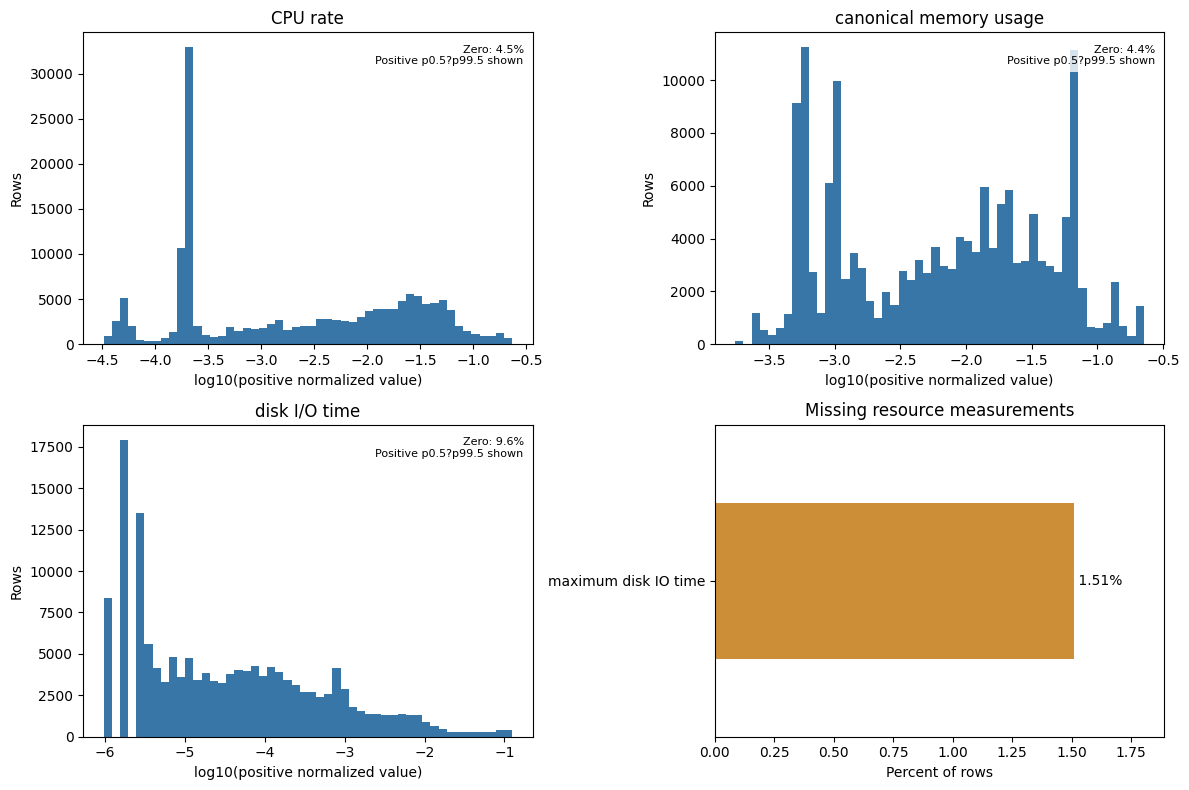

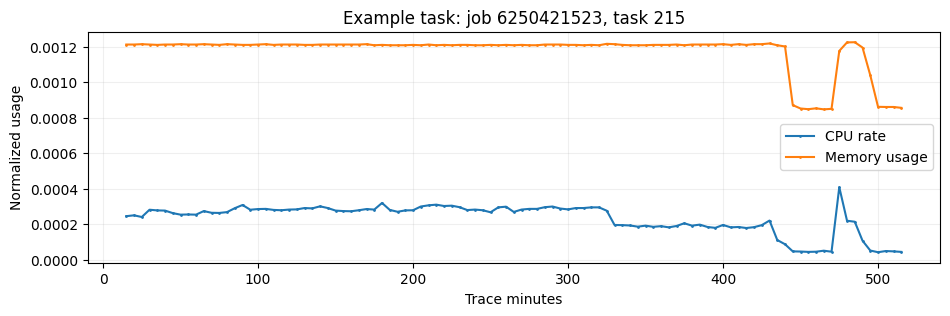

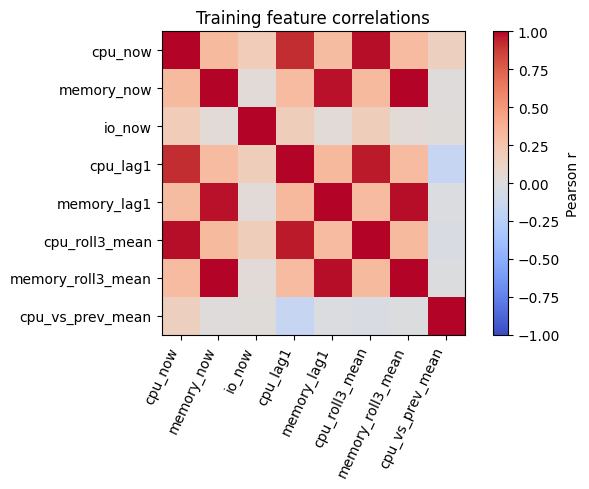

CPU change versus previous interval (training quantiles):


,normalized CPU change
0.50,0.000000
0.90,0.002260
0.99,0.031576


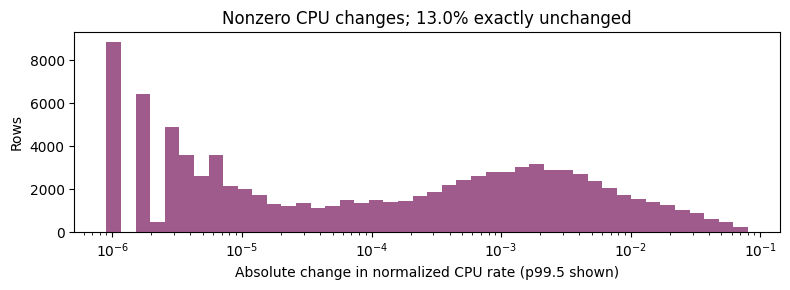

In [7]:
# Positive normalized values span several orders of magnitude. log1p(x) is
# almost unchanged for small x, so use log10 on positive values and report zeros.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, ax in zip(["CPU rate", "canonical memory usage", "disk I/O time"], axes.flat[:3]):
    values = clean[col].dropna().to_numpy()
    positive = values[values > 0]
    zero_pct = 100 * (values == 0).mean() if len(values) else float("nan")
    if len(positive):
        lo, hi = np.quantile(positive, [0.005, 0.995])
        visible = positive[(positive >= lo) & (positive <= hi)]
        ax.hist(np.log10(visible), bins=50, color="#3976a8")
    ax.set(title=col, xlabel="log10(positive normalized value)", ylabel="Rows")
    ax.text(0.98, 0.96, f"Zero: {zero_pct:.1f}%\nPositive p0.5?p99.5 shown",
            transform=ax.transAxes, ha="right", va="top", fontsize=8,
            bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))
missing_rate = (clean[RESOURCE_COLS].isna().mean() * 100).sort_values(ascending=False)
nonzero_missing = missing_rate[missing_rate > 0]
if len(nonzero_missing):
    nonzero_missing.plot.barh(ax=axes[1,1], color="#cc8e37")
    axes[1,1].invert_yaxis()
    for j, value in enumerate(nonzero_missing):
        axes[1,1].text(value, j, f" {value:.2f}%", va="center")
    axes[1,1].set_xlim(0, max(nonzero_missing.max() * 1.25, 1))
else:
    axes[1,1].text(0.5, 0.5, "No missing resource values", ha="center", va="center")
axes[1,1].set(title="Missing resource measurements", xlabel="Percent of rows")
fig.tight_layout()
plt.show()

lengths = clean.groupby(KEY_COLS).size().sort_values(ascending=False)
chosen_key = lengths.index[0]
series = clean.set_index(KEY_COLS).loc[chosen_key].sort_values("start time")
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(series["end time"].to_numpy()/60e6, series["CPU rate"].to_numpy(), label="CPU rate", marker=".", markersize=2)
ax.plot(series["end time"].to_numpy()/60e6, series["canonical memory usage"].to_numpy(), label="Memory usage", marker=".", markersize=2)
ax.set(xlabel="Trace minutes", ylabel="Normalized usage", title=f"Example task: job {int(chosen_key[0])}, task {int(chosen_key[1])}")
ax.legend(); ax.grid(alpha=0.2); plt.show()

corr_cols = [x for x in ["cpu_now", "memory_now", "io_now", "cpu_lag1", "memory_lag1",
                         "cpu_roll3_mean", "memory_roll3_mean", "cpu_vs_prev_mean"] if x in FEATURES]
corr = X_train[corr_cols].corr()
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(corr_cols)), labels=corr_cols, rotation=65, ha="right")
ax.set_yticks(range(len(corr_cols)), labels=corr_cols)
fig.colorbar(im, ax=ax, label="Pearson r")
ax.set_title("Training feature correlations"); fig.tight_layout(); plt.show()
print("CPU change versus previous interval (training quantiles):")
display(X_train["cpu_vs_prev_mean"].quantile([0.5, 0.9, 0.99]).to_frame("normalized CPU change"))

# The original symmetric histogram had a large spike at exactly zero.
# Show nonzero magnitudes on a log scale and report the zero fraction.
burst = X_train["cpu_vs_prev_mean"].to_numpy()
zero_delta_pct = 100 * np.mean(burst == 0)
magnitudes = np.abs(burst[burst != 0])
fig, ax = plt.subplots(figsize=(8, 3))
if len(magnitudes):
    upper = np.quantile(magnitudes, 0.995)
    ax.hist(magnitudes[magnitudes <= upper], bins=np.logspace(np.log10(magnitudes.min()),
            np.log10(max(upper, magnitudes.min() * 1.01)), 45), color="#a05b8d")
    ax.set_xscale("log")
ax.set(title=f"Nonzero CPU changes; {zero_delta_pct:.1f}% exactly unchanged",
       xlabel="Absolute change in normalized CPU rate (p99.5 shown)", ylabel="Rows")
fig.tight_layout(); plt.show()


### Save the Module 2 handoff

The output stores raw, time-safe features from regular 300-second intervals, identity/time audit columns, targets, and the split label. Models should use only `FEATURES`; job/task/machine IDs and timestamps are for grouping and auditing. `X_train`, `X_valid`, and `X_test` above apply the saved training medians. Module 3 may fit scalers or models on `X_train` only. The preparation subset is an identity-hash sample from about 8.42 hours and can overrepresent long-lived tasks.


In [8]:
FEATURE_META = {
    "module": 2,
    "source_parquet": str(PARQUET_PATH),
    "source_rows": int(len(usage)),
    "feature_rows": int(len(model_data)),
    "prediction_horizon_seconds": 300,
    "features": FEATURES,
    "feature_definitions": feature_definitions,
    "train_medians": {name: float(value) for name, value in train_medians.items()},
    "target_columns": ["target_cpu", "target_memory"],
    "split_boundaries_us": {"train_end": train_cut, "validation_end": valid_cut},
    "report": report,
    "seed": SEED,
    "limitations": ["Identity-hash sample from selected first six shards only",
                    "Irregular-duration intervals excluded from fixed-horizon modeling",
                    "Future intervals of observed workloads; not unseen-job generalization",
                    "Usage is observed consumption, not unconstrained resource demand"],
}
TEMP_FEATURES = FEATURES_PATH.with_suffix(".parquet.part")
try:
    model_data.to_parquet(TEMP_FEATURES, index=False, compression="zstd")
    if project_bytes() > MAX_PROJECT_BYTES:
        raise RuntimeError("Module 2 output would exceed the 2.5 GB data/artifact cap")
    TEMP_FEATURES.replace(FEATURES_PATH)
except Exception:
    TEMP_FEATURES.unlink(missing_ok=True)
    raise
atomic_json(FEATURE_META_PATH, FEATURE_META)
print("Saved:", FEATURES_PATH, f"({FEATURES_PATH.stat().st_size/1e6:.2f} MB)")
print("Metadata:", FEATURE_META_PATH)
print("Project data/artifacts:", f"{project_bytes()/1e6:.1f} MB")


Saved: /content/drive/MyDrive/ml-project/data/processed/module2_features.parquet (8.46 MB)
Metadata: /content/drive/MyDrive/ml-project/artifacts/module2_features.json
Project data/artifacts: 565.8 MB


## Module 3 - Workload clustering and resource-demand prediction

This module can start from the cached Module 2 files. In a fresh Colab session, run the Drive/setup cell near the top of this notebook, then start here; the data-preparation notebook is not needed. Clusters describe **interval-level historical profiles**, so one task may move between clusters over time. All cluster preprocessing, imputation, and model fitting use the training period only. Validation selects models; test data is evaluated once after selection.


In [9]:
import time
import joblib
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

FEATURES_PATH = PROJECT_DIR / "data" / "processed" / "module2_features.parquet"
FEATURE_META_PATH = PROJECT_DIR / "artifacts" / "module2_features.json"
MODEL_PATH = PROJECT_DIR / "artifacts" / "module3_models.joblib"
RESULTS_PATH = PROJECT_DIR / "artifacts" / "module3_results.json"
PREDICTIONS_PATH = PROJECT_DIR / "data" / "processed" / "module3_predictions.parquet"
MAX_PROJECT_BYTES = 2_500_000_000
SEED = 42
if not FEATURES_PATH.is_file() or not FEATURE_META_PATH.is_file():
    raise FileNotFoundError("Module 2 outputs are missing. Run Module 2 first.")
with FEATURE_META_PATH.open(encoding="utf-8") as f:
    feature_meta = json.load(f)
model_data = pd.read_parquet(FEATURES_PATH)
if len(model_data) != feature_meta["feature_rows"] or feature_meta.get("prediction_horizon_seconds") != 300:
    raise ValueError("Module 2 feature file/metadata mismatch or non-300-second target horizon")
FEATURES = list(feature_meta["features"])
medians = pd.Series(feature_meta["train_medians"], dtype="float64").reindex(FEATURES)
if medians.isna().any(): raise ValueError("Missing training-only imputation medians")
train_mask = model_data["split"].eq("train")
valid_mask = model_data["split"].eq("validation")
test_mask = model_data["split"].eq("test")
if not all(mask.any() for mask in [train_mask, valid_mask, test_mask]):
    raise ValueError("One or more Module 2 time splits are empty")
# All-constant predictors add no information and can distort clustering.
variable_features = [col for col in FEATURES if model_data.loc[train_mask, col].nunique(dropna=True) > 1]
constant_features = sorted(set(FEATURES) - set(variable_features))
if not variable_features: raise ValueError("No variable predictors remain")
X_train = model_data.loc[train_mask, variable_features].fillna(medians).astype("float32")
X_valid = model_data.loc[valid_mask, variable_features].fillna(medians).astype("float32")
X_test = model_data.loc[test_mask, variable_features].fillna(medians).astype("float32")
for name, frame in [("train", X_train), ("validation", X_valid), ("test", X_test)]:
    if not np.isfinite(frame.to_numpy()).all(): raise ValueError(f"Non-finite {name} predictors")
TARGETS = {"cpu": ("target_cpu", "cpu_now"), "memory": ("target_memory", "memory_now")}
print("Loaded Module 2:", len(model_data), "eligible pairs")
print("Splits:", model_data["split"].value_counts().to_dict())
print("Using", len(variable_features), "predictors; dropping constant:", constant_features)

def project_bytes():
    return sum(p.stat().st_size for root in (PROJECT_DIR / "data", PROJECT_DIR / "artifacts")
               for p in root.rglob("*") if p.is_file())


Loaded Module 2: 159546 eligible pairs
Splits: {'train': 108945, 'test': 24483, 'validation': 22864, 'purged': 3254}
Using 23 predictors; dropping constant: ['interval_seconds']


### Workload patterns

Use current and recent CPU, memory, and disk I/O statistics. A training-only 99.5th percentile cap keeps a few extreme values from defining all cluster centers; raw values remain unchanged in the forecasting table and cluster summaries. Standardize these profiles using training rows. Try 2-6 clusters and choose the best valid silhouette on a 1,500-row **training** sample. PCA is fitted on training rows only for a two-dimensional picture; its axes are visualization coordinates, not new resource units.

A model can train quickly and still be a valid result. On this trace, the previous interval is a strong baseline. The forest is retained as an alternative for later allocation simulation because its validation RMSE can reveal a different trade-off, even if it does not win MAE.


,k,silhouette,smallest_scoring_cluster
0,2,0.624843,282
1,3,0.505969,120
2,4,0.582916,30
3,5,NaN,17
4,6,NaN,12


Chosen k: 2 (training silhouette: 0.625 )


,train_rows,cpu_now,memory_now,io_now,cpu_roll3_std,memory_roll3_std
cluster,,,,,,
0,88176,0.000249,0.002522,0.000006,0.000006,0.000004
1,20769,0.045650,0.065060,0.000329,0.003027,0.000141


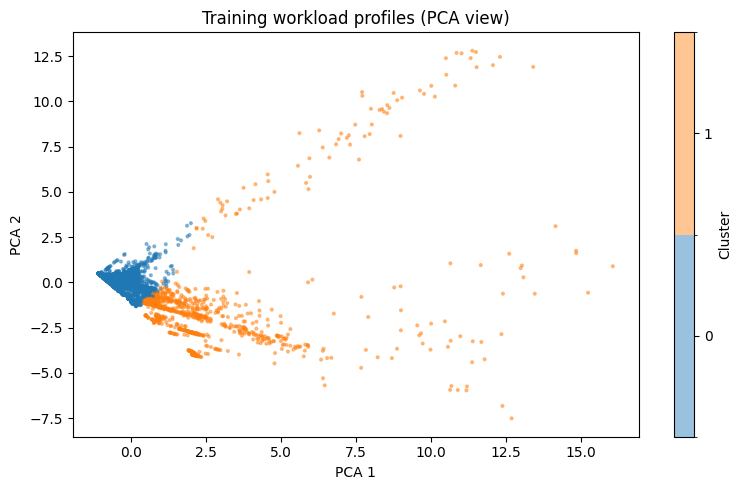

PCA variance shown: 0.669
Interpret clusters from the median resource values above; mixed profiles are valid.


In [10]:
PROFILE_FEATURES = [x for x in ["cpu_now", "memory_now", "io_now",
                              "cpu_roll3_mean", "memory_roll3_mean", "io_roll3_mean",
                              "cpu_roll3_std", "memory_roll3_std", "io_roll3_std"]
                    if x in variable_features]
if len(PROFILE_FEATURES) < 3: raise ValueError("Too few resource profile features for clustering")
profile_upper = X_train[PROFILE_FEATURES].quantile(0.995).clip(lower=1e-12)

def scaled_profiles(frame):
    raw = frame[PROFILE_FEATURES].clip(lower=0, upper=profile_upper, axis="columns")
    return profile_scaler.transform(raw)

rng = np.random.default_rng(SEED)
fit_indices = rng.choice(len(X_train), size=min(30_000, len(X_train)), replace=False)
profile_fit = X_train.iloc[fit_indices][PROFILE_FEATURES].clip(lower=0, upper=profile_upper, axis="columns")
profile_scaler = StandardScaler().fit(profile_fit)
fit_scaled = profile_scaler.transform(profile_fit)
score_indices = rng.choice(len(fit_scaled), size=min(1_500, len(fit_scaled)), replace=False)
cluster_scores = []
cluster_candidates = {}
for k in range(2, 7):
    candidate = MiniBatchKMeans(n_clusters=k, random_state=SEED, batch_size=2048,
                                n_init=3, max_iter=100).fit(fit_scaled)
    labels = candidate.predict(fit_scaled[score_indices])
    counts = np.bincount(labels, minlength=k)
    score = (float(silhouette_score(fit_scaled[score_indices], labels))
             if (counts >= 20).all() else None)
    cluster_scores.append({"k": k, "silhouette": score,
                           "smallest_scoring_cluster": int(counts.min())})
    cluster_candidates[k] = candidate
score_table = pd.DataFrame(cluster_scores)
display(score_table)
valid_scores = score_table.dropna(subset=["silhouette"])
if valid_scores.empty: raise ValueError("No supported cluster count; inspect the profile sample")
best_k = int(valid_scores.sort_values(["silhouette", "k"], ascending=[False, True]).iloc[0]["k"])
cluster_model = cluster_candidates[best_k]
cluster_train = cluster_model.predict(scaled_profiles(X_train))
cluster_valid = cluster_model.predict(scaled_profiles(X_valid))
cluster_test = cluster_model.predict(scaled_profiles(X_test))
profile_summary = X_train[[x for x in ["cpu_now", "memory_now", "io_now",
                                            "cpu_roll3_std", "memory_roll3_std"]
                                   if x in X_train.columns]].copy()
profile_summary["cluster"] = cluster_train
cluster_counts = profile_summary["cluster"].value_counts().sort_index()
cluster_summary = profile_summary.groupby("cluster").median()
cluster_summary.insert(0, "train_rows", cluster_counts)
print("Chosen k:", best_k, "(training silhouette:",
      round(float(valid_scores.loc[valid_scores["k"] == best_k, "silhouette"].iloc[0]), 3), ")")
display(cluster_summary)

pca = PCA(n_components=2, random_state=SEED).fit(fit_scaled)
plot_indices = rng.choice(len(fit_scaled), size=min(5_000, len(fit_scaled)), replace=False)
plot_xy = pca.transform(fit_scaled[plot_indices])
plot_labels = cluster_model.predict(fit_scaled[plot_indices])
from matplotlib.colors import BoundaryNorm, ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
cmap = ListedColormap(plt.get_cmap("tab10").colors[:best_k])
norm = BoundaryNorm(np.arange(-0.5, best_k + 0.5, 1), cmap.N)
scatter = ax.scatter(plot_xy[:, 0], plot_xy[:, 1], c=plot_labels, s=4, alpha=0.45,
                     cmap=cmap, norm=norm, rasterized=True)
ax.set(xlabel="PCA 1", ylabel="PCA 2", title="Training workload profiles (PCA view)")
fig.colorbar(scatter, ax=ax, ticks=range(best_k), label="Cluster")
fig.tight_layout(); plt.show()
print("PCA variance shown:", round(float(pca.explained_variance_ratio_.sum()), 3))
print("Interpret clusters from the median resource values above; mixed profiles are valid.")


### Next-interval CPU and memory forecasts

Compare a persistence baseline (`next = current`), Ridge regression with training-only scaling, and a bounded random forest. The forest uses up to 50,000 reproducibly sampled training rows, 80 trees, depth 12, and one CPU worker. Ridge tests only two `alpha` values. Predictions are clipped at zero for every metric and for the later allocation simulation. Select the lowest validation MAE **separately** for CPU and memory. Test labels are not read during selection.


In [11]:
def evaluate(y_true, y_pred):
    truth = np.asarray(y_true, dtype="float64")
    pred = np.maximum(0, np.asarray(y_pred, dtype="float64"))
    return {"MAE": float(mean_absolute_error(truth, pred)),
            "RMSE": float(np.sqrt(mean_squared_error(truth, pred))),
            "R2": float(r2_score(truth, pred)) if np.unique(truth).size > 1 else None}

forest_indices = rng.choice(len(X_train), size=min(50_000, len(X_train)), replace=False)
model_candidates = {}
validation_predictions = {}
validation_records = []
for resource, (target_col, current_col) in TARGETS.items():
    y_train = model_data.loc[train_mask, target_col]
    y_valid = model_data.loc[valid_mask, target_col]
    candidates = {}
    preds = {}
    preds["persistence"] = X_valid[current_col].to_numpy()
    validation_records.append({"resource": resource, "model": "persistence", "fit_seconds": 0.0,
                               "training_rows": 0, **evaluate(y_valid, preds["persistence"])})
    for alpha in (1.0, 10.0):
        name = f"ridge_alpha_{alpha:g}"
        model = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
        started = time.perf_counter()
        model.fit(X_train, y_train)
        elapsed = time.perf_counter() - started
        candidates[name] = model
        preds[name] = model.predict(X_valid)
        validation_records.append({"resource": resource, "model": name,
                                   "fit_seconds": round(elapsed, 2),
                                   "training_rows": len(X_train), **evaluate(y_valid, preds[name])})
    name = "random_forest"
    forest = RandomForestRegressor(n_estimators=80, max_depth=12, min_samples_leaf=8,
                                   max_features=0.8, n_jobs=1, random_state=SEED)
    started = time.perf_counter()
    forest.fit(X_train.iloc[forest_indices], y_train.iloc[forest_indices])
    elapsed = time.perf_counter() - started
    candidates[name] = forest
    preds[name] = forest.predict(X_valid)
    validation_records.append({"resource": resource, "model": name,
                               "fit_seconds": round(elapsed, 2),
                               "training_rows": len(forest_indices), **evaluate(y_valid, preds[name])})
    model_candidates[resource] = candidates
    validation_predictions[resource] = preds

validation_table = pd.DataFrame(validation_records).sort_values(["resource", "MAE", "model"])
selected_names = {resource: str(group.iloc[0]["model"])
                  for resource, group in validation_table.groupby("resource", sort=False)}
print("Validation metrics; lower MAE/RMSE and higher R2 are better:")
display(validation_table)
print("Selected by validation MAE:", selected_names)
for resource in TARGETS:
    baseline = validation_table.loc[(validation_table["resource"] == resource)
                                    & (validation_table["model"] == "persistence"), "MAE"].iloc[0]
    winner = validation_table.loc[(validation_table["resource"] == resource)
                                  & (validation_table["model"] == selected_names[resource]), "MAE"].iloc[0]
    print(resource, "validation MAE improvement vs persistence:", f"{(baseline-winner)/baseline:.1%}" if baseline else "undefined")


Validation metrics; lower MAE/RMSE and higher R2 are better:


,resource,model,fit_seconds,training_rows,MAE,RMSE,R2
0,cpu,persistence,0.00,0,0.002796,0.010156,0.914177
3,cpu,random_forest,57.81,50000,0.002842,0.009656,0.922415
2,cpu,ridge_alpha_10,0.06,108945,0.003042,0.009790,0.920256
1,cpu,ridge_alpha_1,0.05,108945,0.003044,0.009806,0.919994
4,memory,persistence,0.00,0,0.000428,0.003437,0.991493
7,memory,random_forest,55.22,50000,0.000446,0.003092,0.993116
6,memory,ridge_alpha_10,0.08,108945,0.000529,0.003161,0.992806
5,memory,ridge_alpha_1,0.05,108945,0.000534,0.003169,0.992771


Selected by validation MAE: {'cpu': 'persistence', 'memory': 'persistence'}
cpu validation MAE improvement vs persistence: 0.0%
memory validation MAE improvement vs persistence: 0.0%


In [12]:
# Secondary validation view: RMSE emphasizes large errors. This does not
# change the selected model, which remains the MAE winner above.
for resource in TARGETS:
    rows = validation_table.loc[validation_table["resource"] == resource].set_index("model")
    baseline_rmse = rows.loc["persistence", "RMSE"]
    forest_rmse = rows.loc["random_forest", "RMSE"]
    print(resource, "forest validation RMSE change vs persistence:",
          f"{(forest_rmse-baseline_rmse)/baseline_rmse:+.1%}")


cpu forest validation RMSE change vs persistence: -4.9%
memory forest validation RMSE change vs persistence: -10.0%


Final test metrics:


,resource,model,MAE,RMSE,R2
0,cpu,persistence,0.003181,0.010471,0.902727
1,memory,persistence,0.000450,0.003065,0.993012


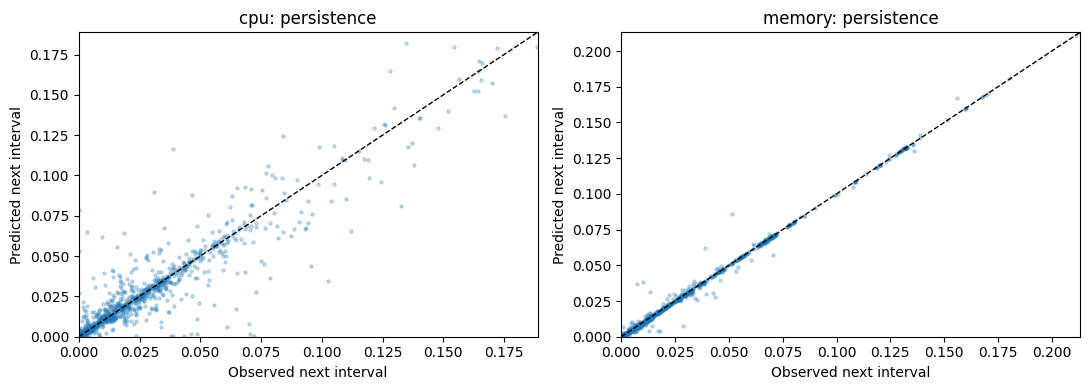

Plots show a fixed random sample and the 99th-percentile view; metrics use all test rows.


In [13]:
# The model names above are now frozen. Evaluate the untouched test period once.
test_records = []
test_predictions = {}
for resource, (target_col, current_col) in TARGETS.items():
    y_test = model_data.loc[test_mask, target_col]
    base = X_test[current_col].to_numpy()
    name = selected_names[resource]
    chosen = base if name == "persistence" else model_candidates[resource][name].predict(X_test)
    chosen = np.maximum(0, np.asarray(chosen, dtype="float64"))
    test_predictions[resource] = chosen
    test_records.append({"resource": resource, "model": "persistence", **evaluate(y_test, base)})
    if name != "persistence":
        test_records.append({"resource": resource, "model": name, **evaluate(y_test, chosen)})
test_table = pd.DataFrame(test_records)
print("Final test metrics:")
display(test_table)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, resource in zip(axes, TARGETS):
    truth = model_data.loc[test_mask, TARGETS[resource][0]].to_numpy()
    pred = test_predictions[resource]
    sample = rng.choice(len(truth), size=min(2_000, len(truth)), replace=False)
    limit = max(1e-6, float(np.quantile(np.concatenate([truth[sample], pred[sample]]), 0.99)))
    ax.scatter(truth[sample], pred[sample], s=5, alpha=0.25)
    ax.plot([0, limit], [0, limit], color="black", linestyle="--", linewidth=1)
    ax.set(xlim=(0, limit), ylim=(0, limit), xlabel="Observed next interval",
           ylabel="Predicted next interval", title=f"{resource}: {selected_names[resource]}")
fig.tight_layout(); plt.show()
print("Plots show a fixed random sample and the 99th-percentile view; metrics use all test rows.")


### Save models and predictions for Module 4

The saved bundle includes the training medians, selected model for each resource, clustering scaler/caps/model, and PCA. The predictions file contains validation and test rows with observed targets, persistence forecasts, selected ML forecasts, and cluster assignments. The chosen model may be persistence if it wins validation; that is an honest outcome. The random forest is also saved as an **alternative candidate** for Module 5, where allocation margins can be tuned on validation data. It is not relabeled as the MAE winner. All saved forecasts are nonnegative, matching the metrics and later simulation.


In [14]:
selected_models = {resource: (None if selected_names[resource] == "persistence"
                              else model_candidates[resource][selected_names[resource]])
                   for resource in TARGETS}
model_bundle = {"features": variable_features, "training_medians": medians.to_dict(),
                "selected_names": selected_names, "selected_models": selected_models,
                "cluster_features": PROFILE_FEATURES, "cluster_upper": profile_upper.to_dict(),
                "cluster_scaler": profile_scaler, "cluster_model": cluster_model,
                "pca": pca, "seed": SEED, "horizon_seconds": 300,
                "alternative_forest_models": {resource: model_candidates[resource]["random_forest"]
                                              for resource in TARGETS}}

handoff = model_data.loc[valid_mask | test_mask,
                         ["split", "job ID", "task index", "machine ID", "end time",
                          "target_end", "target_cpu", "target_memory"]].copy()
valid_index = model_data.index[valid_mask]
test_index = model_data.index[test_mask]
handoff.loc[valid_index, "cluster"] = cluster_valid
handoff.loc[test_index, "cluster"] = cluster_test
handoff["cluster"] = handoff["cluster"].astype("int16")
for resource, (target_col, current_col) in TARGETS.items():
    valid_chosen = validation_predictions[resource][selected_names[resource]]
    handoff.loc[valid_index, f"persistence_{resource}"] = X_valid[current_col].to_numpy()
    handoff.loc[test_index, f"persistence_{resource}"] = X_test[current_col].to_numpy()
    handoff.loc[valid_index, f"pred_{resource}"] = np.maximum(0, valid_chosen)
    handoff.loc[test_index, f"pred_{resource}"] = test_predictions[resource]
    handoff.loc[valid_index, f"forest_pred_{resource}"] = np.maximum(
        0, validation_predictions[resource]["random_forest"])
    handoff.loc[test_index, f"forest_pred_{resource}"] = np.maximum(
        0, model_candidates[resource]["random_forest"].predict(X_test))
    if not np.isfinite(handoff[[f"pred_{resource}", f"forest_pred_{resource}"]].to_numpy()).all():
        raise ValueError(f"Non-finite {resource} forecasts")

results = {"module": 3, "source_feature_file": str(FEATURES_PATH),
           "selected_models": selected_names, "features": variable_features,
           "dropped_constant_features": constant_features,
           "cluster_k": best_k, "cluster_scores": cluster_scores,
           "cluster_profile_medians": cluster_summary.reset_index().to_dict(orient="records"),
           "pca_variance_ratio": pca.explained_variance_ratio_.tolist(),
           "validation_metrics": validation_records, "test_metrics": test_records,
           "forest_training_rows": len(forest_indices), "seed": SEED,
           "alternative_forest_saved": True,
           "selection_rule": "Lowest validation MAE; forest retained only as alternative"}

TEMP_MODEL = MODEL_PATH.with_suffix(".joblib.part")
TEMP_PRED = PREDICTIONS_PATH.with_suffix(".parquet.part")
TEMP_RESULTS = RESULTS_PATH.with_suffix(".json.part")
try:
    joblib.dump(model_bundle, TEMP_MODEL, compress=3)
    handoff.to_parquet(TEMP_PRED, index=False, compression="zstd")
    TEMP_RESULTS.write_text(json.dumps(results, indent=2, allow_nan=False), encoding="utf-8")
    if project_bytes() > MAX_PROJECT_BYTES:
        raise RuntimeError("Module 3 artifacts would exceed the 2.5 GB project cap")
    TEMP_MODEL.replace(MODEL_PATH)
    TEMP_PRED.replace(PREDICTIONS_PATH)
    TEMP_RESULTS.replace(RESULTS_PATH)
except Exception:
    for path in (TEMP_MODEL, TEMP_PRED, TEMP_RESULTS): path.unlink(missing_ok=True)
    raise
print("Saved models:", MODEL_PATH)
print("Saved predictions:", PREDICTIONS_PATH, f"({PREDICTIONS_PATH.stat().st_size/1e6:.2f} MB)")
print("Saved results:", RESULTS_PATH)
print("Project data/artifacts:", f"{project_bytes()/1e6:.1f} MB")


Saved models: /content/drive/MyDrive/ml-project/artifacts/module3_models.joblib
Saved predictions: /content/drive/MyDrive/ml-project/data/processed/module3_predictions.parquet (1.18 MB)
Saved results: /content/drive/MyDrive/ml-project/artifacts/module3_results.json
Project data/artifacts: 565.8 MB


## Module 4 - Potential allocation-risk classification

In a fresh Colab session, run the Drive/setup cell near the top of the notebook, then start Module 4; its feature and forecast tables load from saved files.

The Google trace contains **observed resource usage**, not verified bottleneck incidents or unmet demand. Define a *simulated reference allocation* for CPU and memory as the **training-period 90th percentile of next-interval usage** for each resource, with a small positive floor. Freeze those two numbers for validation and test. A future interval is labeled `balanced`, `CPU risk`, `memory risk`, or `both` according to which observed usages exceed the reference. These are rule-derived **proxy labels**, not production failures. Task-level risk can still vary over time.

Classifiers receive only the historical features from Module 2, including the current interval and earlier ones. The next-interval targets are used solely to create labels and evaluate predictions. They are never classifier inputs. A majority-class baseline makes the value of the classifiers visible.


In [15]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, precision_recall_fscore_support, classification_report, confusion_matrix
from IPython.display import display

FEATURES_PATH = PROJECT_DIR / "data" / "processed" / "module2_features.parquet"
FEATURE_META_PATH = PROJECT_DIR / "artifacts" / "module2_features.json"
M3_PREDICTIONS_PATH = PROJECT_DIR / "data" / "processed" / "module3_predictions.parquet"
M4_MODEL_PATH = PROJECT_DIR / "artifacts" / "module4_classifier.joblib"
M4_RESULTS_PATH = PROJECT_DIR / "artifacts" / "module4_results.json"
M4_PREDICTIONS_PATH = PROJECT_DIR / "data" / "processed" / "module4_predictions.parquet"
MAX_PROJECT_BYTES = 2_500_000_000
SEED = 42
if not FEATURES_PATH.is_file() or not FEATURE_META_PATH.is_file():
    raise FileNotFoundError("Module 2 feature outputs are missing")
if not M3_PREDICTIONS_PATH.is_file():
    raise FileNotFoundError("Module 3 predictions are missing; run its save cell first")
with FEATURE_META_PATH.open(encoding="utf-8") as f:
    m2_meta = json.load(f)
model_data = pd.read_parquet(FEATURES_PATH)
if len(model_data) != m2_meta["feature_rows"] or m2_meta.get("prediction_horizon_seconds") != 300:
    raise ValueError("Module 2 features or prediction horizon changed")
train_mask = model_data["split"].eq("train")
valid_mask = model_data["split"].eq("validation")
test_mask = model_data["split"].eq("test")
if not all(mask.any() for mask in [train_mask, valid_mask, test_mask]):
    raise ValueError("A time split is empty")
features = [name for name in m2_meta["features"]
            if model_data.loc[train_mask, name].nunique(dropna=True) > 1]
if not features or set(features) & {"target_cpu", "target_memory", "job ID", "task index", "machine ID"}:
    raise ValueError("Invalid historical feature list")
train_medians = pd.Series(m2_meta["train_medians"], dtype="float64").reindex(features)
if train_medians.isna().any(): raise ValueError("Missing training-only feature medians")
X_train = model_data.loc[train_mask, features].fillna(train_medians).astype("float32")
X_valid = model_data.loc[valid_mask, features].fillna(train_medians).astype("float32")
X_test = model_data.loc[test_mask, features].fillna(train_medians).astype("float32")
for name, frame in [("train", X_train), ("validation", X_valid), ("test", X_test)]:
    if not np.isfinite(frame.to_numpy()).all(): raise ValueError(f"Non-finite {name} features")
print("Historical predictors:", len(features), "| split rows:",
      {name: len(frame) for name, frame in [("train", X_train), ("validation", X_valid), ("test", X_test)]})

def project_bytes():
    return sum(p.stat().st_size for root in (PROJECT_DIR / "data", PROJECT_DIR / "artifacts")
               for p in root.rglob("*") if p.is_file())


Historical predictors: 23 | split rows: {'train': 108945, 'validation': 22864, 'test': 24483}


### Fixed reference and proxy labels

The reference is deliberately simple: the same simulated allocation for every task. It is not a recorded CPU/memory request, and an exceedance does not prove a scheduling failure. Percentiles are calculated **once from training labels** and then frozen. Display the support for every class in each time split; imbalanced or absent classes affect how the scores should be read.


In [16]:
LABELS = ["balanced", "CPU risk", "memory risk", "both"]
CPU_ALLOCATION = max(1e-6, float(model_data.loc[train_mask, "target_cpu"].quantile(0.90)))
MEMORY_ALLOCATION = max(1e-6, float(model_data.loc[train_mask, "target_memory"].quantile(0.90)))

def proxy_labels(frame):
    cpu_over = frame["target_cpu"].to_numpy() > CPU_ALLOCATION
    memory_over = frame["target_memory"].to_numpy() > MEMORY_ALLOCATION
    codes = cpu_over.astype("int8") + 2 * memory_over.astype("int8")
    return np.array(LABELS, dtype=object)[codes]  # 0 balanced, 1 CPU, 2 memory, 3 both

y_train = proxy_labels(model_data.loc[train_mask])
y_valid = proxy_labels(model_data.loc[valid_mask])
y_test = proxy_labels(model_data.loc[test_mask])
if len(np.unique(y_train)) < 2:
    raise ValueError("Training proxy labels contain fewer than two classes")
class_counts = pd.DataFrame({name: pd.Series(y).value_counts().reindex(LABELS, fill_value=0)
                             for name, y in [("train", y_train), ("validation", y_valid), ("test", y_test)]})
print(f"Frozen simulated allocation: CPU={CPU_ALLOCATION:.6g}, memory={MEMORY_ALLOCATION:.6g}")
display(class_counts)
rare = class_counts.index[class_counts["train"] < 30].tolist()
if rare: print("Training classes with fewer than 30 rows:", rare, "(interpret their metrics cautiously)")


Frozen simulated allocation: CPU=0.05072, memory=0.06677


,train,validation,test
balanced,89669,19422,20510
CPU risk,8426,1241,1642
memory risk,8393,1766,1827
both,2457,435,504


### Baseline and classifiers

Compare the training majority class, a balanced logistic regression with training-only scaling, and a bounded balanced decision tree. Validation **macro-F1** selects one classifier; it gives each of the four proxy classes equal weight. Report each class's recall alongside macro-F1 so a strong overall score cannot hide missed risk categories. There is no random reshuffling across trace time.


In [17]:
def class_metrics(y_true, y_pred):
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=LABELS, zero_division=0)
    return {"macro_F1": float(f1_score(y_true, y_pred, labels=LABELS,
                                        average="macro", zero_division=0)),
            "recall": {label: float(value) for label, value in zip(LABELS, recall)},
            "support": {label: int(value) for label, value in zip(LABELS, support)}}

candidates = {
    "majority": DummyClassifier(strategy="most_frequent"),
    "logistic_regression": make_pipeline(StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=700, solver="lbfgs", random_state=SEED)),
    "decision_tree": DecisionTreeClassifier(max_depth=7, min_samples_leaf=100,
        class_weight="balanced", random_state=SEED),
}
validation_records = []
validation_predictions = {}
for name, classifier in candidates.items():
    classifier.fit(X_train, y_train)
    predicted = classifier.predict(X_valid)
    validation_predictions[name] = predicted
    metrics = class_metrics(y_valid, predicted)
    validation_records.append({"model": name, "macro_F1": metrics["macro_F1"],
                               **{f"recall_{label}": metrics["recall"][label] for label in LABELS}})
validation_table = pd.DataFrame(validation_records).sort_values(["macro_F1", "model"], ascending=[False, True])
selected_name = str(validation_table.iloc[0]["model"])
selected_classifier = candidates[selected_name]
print("Validation model comparison:")
display(validation_table)
print("Selected by validation macro-F1:", selected_name)


Validation model comparison:


,model,macro_F1,recall_balanced,recall_CPU risk,recall_memory risk,recall_both
2,decision_tree,0.868807,0.957780,0.919420,0.964892,0.928736
1,logistic_regression,0.829041,0.949593,0.807413,0.975085,0.947126
0,majority,0.229650,1.000000,0.000000,0.000000,0.000000


Selected by validation macro-F1: decision_tree


Held-out test report for decision_tree
              precision    recall  f1-score   support

    balanced       1.00      0.95      0.97     20510
    CPU risk       0.65      0.92      0.76      1642
 memory risk       0.96      0.97      0.96      1827
        both       0.70      0.94      0.80       504

    accuracy                           0.95     24483
   macro avg       0.83      0.95      0.88     24483
weighted avg       0.96      0.95      0.96     24483

Test macro-F1 - selected: 0.8752 | majority: 0.2279


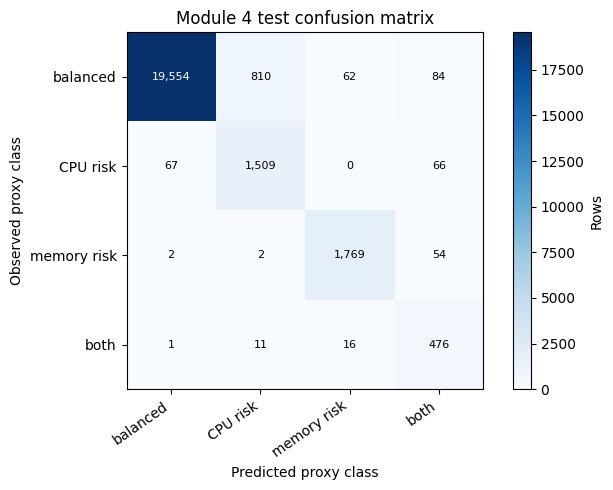

In [18]:
# The selection above is frozen before evaluating the held-out test labels.
test_pred = selected_classifier.predict(X_test)
majority_test_pred = candidates["majority"].predict(X_test)
print("Held-out test report for", selected_name)
print(classification_report(y_test, test_pred, labels=LABELS, zero_division=0))
print("Test macro-F1 - selected:", round(class_metrics(y_test, test_pred)["macro_F1"], 4),
      "| majority:", round(class_metrics(y_test, majority_test_pred)["macro_F1"], 4))
cm = confusion_matrix(y_test, test_pred, labels=LABELS)
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(LABELS)), LABELS, rotation=35, ha="right")
ax.set_yticks(range(len(LABELS)), LABELS)
ax.set(xlabel="Predicted proxy class", ylabel="Observed proxy class", title="Module 4 test confusion matrix")
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        ax.text(j, i, f"{cm[i,j]:,}", ha="center", va="center",
                color="white" if cm[i,j] > cm.max()/2 else "black", fontsize=8)
fig.colorbar(im, ax=ax, label="Rows")
fig.tight_layout(); plt.show()


### Inspect examples and save the handoff

The examples below join proxy risk labels and historical profiles to Module 3 demand forecasts **for explanation only**. The classifier was fitted without those forecasts or the future targets. The same fixed reference defines ground truth for every later allocation policy; Module 5 must not recalculate labels separately for each policy.


In [19]:
# Keep the original time-split row index for precise alignment, then save compact outputs.
valid_index = model_data.index[valid_mask]
test_index = model_data.index[test_mask]
classified = model_data.loc[valid_mask | test_mask,
    ["split", "job ID", "task index", "end time", "target_end",
     "target_cpu", "target_memory", "cpu_now", "memory_now"]].copy()
classified.loc[valid_index, "proxy_label"] = y_valid
classified.loc[test_index, "proxy_label"] = y_test
classified.loc[valid_index, "predicted_label"] = validation_predictions[selected_name]
classified.loc[test_index, "predicted_label"] = test_pred
classified.reset_index(drop=True, inplace=True)

forecast = pd.read_parquet(M3_PREDICTIONS_PATH)
join_keys = ["split", "job ID", "task index", "end time"]
if forecast.duplicated(join_keys).any() or classified.duplicated(join_keys).any():
    raise ValueError("Duplicate task-time keys prevent unambiguous forecast alignment")
forecast_cols = join_keys + ["pred_cpu", "pred_memory", "forest_pred_cpu", "forest_pred_memory"]
if not set(forecast_cols).issubset(forecast.columns):
    raise ValueError("Run the refreshed Module 3 save cell to add alternative forecasts")
examples = classified.merge(forecast[forecast_cols], on=join_keys, how="left", validate="one_to_one")
if examples[["pred_cpu", "pred_memory"]].isna().any().any():
    raise ValueError("Missing Module 3 forecasts after joining by task and time")
print("Sample potential-risk intervals (normalized usage; thresholds above):")
risky = examples.loc[examples["proxy_label"] != "balanced"]
display(risky[["proxy_label", "predicted_label", "cpu_now", "memory_now",
               "target_cpu", "target_memory", "pred_cpu", "pred_memory"]].head(5))

bundle = {"selected_name": selected_name, "classifier": selected_classifier,
          "features": features, "training_medians": train_medians.to_dict(),
          "labels": LABELS, "reference_allocation":
          {"cpu": CPU_ALLOCATION, "memory": MEMORY_ALLOCATION}, "seed": SEED}
results = {"module": 4, "label_kind": "simulated_reference_allocation_risk",
           "reference_allocation": {"cpu": CPU_ALLOCATION, "memory": MEMORY_ALLOCATION},
           "class_counts": class_counts.to_dict(), "selected_model": selected_name,
           "validation_metrics": validation_records,
           "test_selected": class_metrics(y_test, test_pred),
           "test_majority": class_metrics(y_test, majority_test_pred),
           "test_confusion_matrix": cm.tolist(), "labels": LABELS,
           "limitations": ["Proxy labels derived from observed future usage, not verified failures",
                           "Fixed allocation is simulated, not a recorded resource request"]}
TEMP_MODEL = M4_MODEL_PATH.with_suffix(".joblib.part")
TEMP_PRED = M4_PREDICTIONS_PATH.with_suffix(".parquet.part")
TEMP_RESULTS = M4_RESULTS_PATH.with_suffix(".json.part")
try:
    joblib.dump(bundle, TEMP_MODEL, compress=3)
    classified.to_parquet(TEMP_PRED, index=False, compression="zstd")
    TEMP_RESULTS.write_text(json.dumps(results, indent=2, allow_nan=False), encoding="utf-8")
    if project_bytes() > MAX_PROJECT_BYTES:
        raise RuntimeError("Module 4 artifacts would exceed the 2.5 GB project cap")
    TEMP_MODEL.replace(M4_MODEL_PATH)
    TEMP_PRED.replace(M4_PREDICTIONS_PATH)
    TEMP_RESULTS.replace(M4_RESULTS_PATH)
except Exception:
    for path in (TEMP_MODEL, TEMP_PRED, TEMP_RESULTS): path.unlink(missing_ok=True)
    raise
print("Saved classifier:", M4_MODEL_PATH)
print("Saved predictions:", M4_PREDICTIONS_PATH, f"({M4_PREDICTIONS_PATH.stat().st_size/1e6:.2f} MB)")
print("Saved results:", M4_RESULTS_PATH)
print("Project data/artifacts:", f"{project_bytes()/1e6:.1f} MB")


Sample potential-risk intervals (normalized usage; thresholds above):


,proxy_label,predicted_label,cpu_now,memory_now,target_cpu,target_memory,pred_cpu,pred_memory
0,memory risk,memory risk,0.002491,0.09094,0.002441,0.09094,0.002491,0.09094
1,memory risk,memory risk,0.002441,0.09094,0.002796,0.09094,0.002441,0.09094
2,memory risk,memory risk,0.002796,0.09094,0.002911,0.09094,0.002796,0.09094
3,memory risk,memory risk,0.002911,0.09094,0.002850,0.09106,0.002911,0.09094
4,memory risk,memory risk,0.002850,0.09106,0.003033,0.09106,0.002850,0.09106


Saved classifier: /content/drive/MyDrive/ml-project/artifacts/module4_classifier.joblib
Saved predictions: /content/drive/MyDrive/ml-project/data/processed/module4_predictions.parquet (0.36 MB)
Saved results: /content/drive/MyDrive/ml-project/artifacts/module4_results.json
Project data/artifacts: 565.8 MB


## Module 5 - Allocation simulation and what-if analysis

In a fresh Colab session, run the Drive/setup cell near the top of this notebook, then start here. This section loads the saved outputs from Modules 2-4; it does not retrain or download anything. It replays the same held-out task intervals for three policies: a fixed per-task reference from Module 4, the last observed demand (persistence), and the **alternative random-forest forecast** from Module 3 plus a validation-tuned safety margin. Module 3 selected persistence for lowest forecasting MAE; the forest remains an explicitly separate candidate for allocation analysis.

This is a **trace replay**, not a Borg scheduler. It treats observed normalized usage as demand for arithmetic purposes, although real observed usage may already reflect scheduling constraints. CPU and memory pools are simulated for the sampled task cohort, not actual machine capacity. No cost, latency, or SLA claim can be inferred from the results.


In [20]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

M2_FEATURES_PATH = PROJECT_DIR / "data" / "processed" / "module2_features.parquet"
M3_PREDICTIONS_PATH = PROJECT_DIR / "data" / "processed" / "module3_predictions.parquet"
M3_RESULTS_PATH = PROJECT_DIR / "artifacts" / "module3_results.json"
M4_PREDICTIONS_PATH = PROJECT_DIR / "data" / "processed" / "module4_predictions.parquet"
M4_RESULTS_PATH = PROJECT_DIR / "artifacts" / "module4_results.json"
M5_RESULTS_PATH = PROJECT_DIR / "artifacts" / "module5_results.json"
M5_TABLE_PATH = PROJECT_DIR / "artifacts" / "module5_policy_metrics.csv"
MAX_PROJECT_BYTES = 2_500_000_000
for path in (M2_FEATURES_PATH, M3_PREDICTIONS_PATH, M3_RESULTS_PATH,
             M4_PREDICTIONS_PATH, M4_RESULTS_PATH):
    if not path.is_file(): raise FileNotFoundError(f"Missing prerequisite: {path}")
with M3_RESULTS_PATH.open(encoding="utf-8") as f: m3_results = json.load(f)
with M4_RESULTS_PATH.open(encoding="utf-8") as f: m4_results = json.load(f)
if not m3_results.get("alternative_forest_saved"):
    raise ValueError("Run the refreshed Module 3 save cell before this simulation")
if m4_results.get("label_kind") != "simulated_reference_allocation_risk":
    raise ValueError("Unexpected Module 4 reference/label definition")
reference = {r: float(m4_results["reference_allocation"][r]) for r in ("cpu", "memory")}
features = pd.read_parquet(M2_FEATURES_PATH,
                           columns=["split", "target_end", "target_cpu", "target_memory"])
train = features.loc[features["split"].eq("train")]
if train.empty: raise ValueError("No training intervals available for pool sizing")
# Training-only aggregate demand for the sampled task cohort at each target interval.
training_totals = train.groupby("target_end")[["target_cpu", "target_memory"]].sum()
pool = {r: max(1e-6, float(training_totals[f"target_{r}"].quantile(0.95)))
        for r in ("cpu", "memory")}

forecast = pd.read_parquet(M3_PREDICTIONS_PATH)
classified = pd.read_parquet(M4_PREDICTIONS_PATH)
keys = ["split", "job ID", "task index", "end time"]
needed = set(keys + ["target_end", "target_cpu", "target_memory",
                     "persistence_cpu", "persistence_memory",
                     "forest_pred_cpu", "forest_pred_memory"])
if not needed.issubset(forecast.columns):
    raise ValueError(f"Missing Module 3 forecast columns: {sorted(needed-set(forecast.columns))}")
if forecast.duplicated(keys).any() or classified.duplicated(keys).any():
    raise ValueError("Duplicate task-time rows in saved handoff")
replay = forecast.merge(classified[keys + ["proxy_label", "predicted_label"]],
                        on=keys, how="inner", validate="one_to_one")
if len(replay) != len(forecast) or len(replay) != len(classified):
    raise ValueError("Module 3/4 saved intervals do not match exactly")
if not replay["split"].isin(["validation", "test"]).all():
    raise ValueError("Replay includes a training or purged interval")
if not replay["target_end"].sub(replay["end time"]).eq(300_000_000).all():
    raise ValueError("Simulation expects exact five-minute target intervals")
for r in ("cpu", "memory"):
    for col in (f"target_{r}", f"persistence_{r}", f"forest_pred_{r}"):
        if not np.isfinite(replay[col]).all() or (replay[col] < 0).any():
            raise ValueError(f"Invalid observed or forecast usage: {col}")
# The proxy label is fixed by future observed usage and the frozen reference.
labels = np.array(["balanced", "CPU risk", "memory risk", "both"])
expected = labels[(replay["target_cpu"].to_numpy() > reference["cpu"]).astype(int)
                  + 2*(replay["target_memory"].to_numpy() > reference["memory"]).astype(int)]
if not np.array_equal(expected, replay["proxy_label"].to_numpy()):
    raise ValueError("Module 4 proxy labels changed from the frozen reference")
validation = replay.loc[replay["split"].eq("validation")].copy()
test = replay.loc[replay["split"].eq("test")].copy()
if validation.empty or test.empty: raise ValueError("Missing validation or test replay rows")
print("Reference per task:", reference)
print("Training-only simulated pool capacity per interval:", pool)
print("Validation rows:", len(validation), "| test rows:", len(test),
      "| training pool intervals:", len(training_totals))


Reference per task: {'cpu': 0.05071999877691269, 'memory': 0.06677000224590302}
Training-only simulated pool capacity per interval: {'cpu': 32.35294036865234, 'memory': 36.560906982421876}
Validation rows: 22864 | test rows: 24483 | training pool intervals: 69


### Replay rule and metrics

At each target time step, each policy proposes CPU and memory allocation **before** seeing that interval's demand. If the sum of requests exceeds a resource pool, every request for that resource is reduced by the same factor, `pool / total_requested`. CPU and memory are scaled independently. This deterministic proportional rule treats all three policies equally. We measure the **achieved allocation after scaling**. All kept intervals are 300 seconds, and formulas still weight each row by its duration.

For observed usage `D` and achieved allocation `A`, report useful utilization `sum(min(D,A)*duration) / sum(A*duration)`, unused allocation `sum(max(A-D,0)*duration)`, unmet observed usage `sum(max(D-A,0)*duration)`, unmet share of observed usage, and the fraction of task intervals with `D>A`. The last measure counts even tiny shortfalls, so compare it with the unmet share to distinguish frequency from severity. Resource amounts are normalized-resource-seconds, **not** billable currency or physical cores/GB.


In [21]:
POLICIES = ["fixed", "persistence", "forest_plus_margin"]
RESOURCES = ["cpu", "memory"]

def desired_allocation(frame, policy, margin=0.0):
    proposed = {}
    for resource in RESOURCES:
        if policy == "fixed":
            proposed[resource] = np.full(len(frame), reference[resource], dtype="float64")
        elif policy == "persistence":
            proposed[resource] = frame[f"persistence_{resource}"].to_numpy(dtype="float64")
        elif policy == "forest_plus_margin":
            # Additive floor is fixed from the training-only reference. It keeps
            # exact-zero forecasts from receiving no allocation at all.
            proposed[resource] = (frame[f"forest_pred_{resource}"].to_numpy(dtype="float64")
                                  * (1.0 + margin) + 0.02 * reference[resource])
        else:
            raise ValueError(f"Unknown policy: {policy}")
    return proposed

def replay_policy(frame, policy, margin=0.0, demand_multiplier=1.0,
                  capacity_multiplier=1.0):
    if frame.empty: raise ValueError("Cannot replay an empty interval set")
    if demand_multiplier <= 0 or capacity_multiplier <= 0:
        raise ValueError("Scenario multipliers must be positive")
    desired = desired_allocation(frame, policy, margin)
    times = frame["target_end"]
    duration = (frame["target_end"] - frame["end time"]).to_numpy(dtype="float64") / 1e6
    result = {}
    for resource in RESOURCES:
        requested = desired[resource]
        if not np.isfinite(requested).all() or (requested < 0).any():
            raise ValueError(f"Invalid {policy} request for {resource}")
        capacity = pool[resource] * capacity_multiplier
        total_requested = pd.Series(requested, index=frame.index).groupby(times).transform("sum").to_numpy()
        scale = np.ones(len(frame), dtype="float64")
        positive = total_requested > 0
        scale[positive] = np.minimum(1.0, capacity / total_requested[positive])
        achieved = requested * scale
        allocated_by_time = pd.Series(achieved, index=frame.index).groupby(times).sum()
        if (allocated_by_time > capacity + 1e-7).any():
            raise AssertionError("A simulated pool limit was exceeded")
        demand = frame[f"target_{resource}"].to_numpy(dtype="float64") * demand_multiplier
        allocated_total = float(np.sum(achieved * duration))
        demand_total = float(np.sum(demand * duration))
        served = float(np.sum(np.minimum(demand, achieved) * duration))
        unused = float(np.sum(np.maximum(achieved - demand, 0) * duration))
        unmet = float(np.sum(np.maximum(demand - achieved, 0) * duration))
        if not np.isclose(served + unused, allocated_total, rtol=1e-7, atol=1e-5):
            raise AssertionError("Allocation accounting does not balance")
        if not np.isclose(served + unmet, demand_total, rtol=1e-7, atol=1e-5):
            raise AssertionError("Demand accounting does not balance")
        saturated_times = pd.Series(total_requested > capacity, index=frame.index).groupby(times).any()
        result[resource] = {
            "utilization": served / allocated_total if allocated_total else None,
            "allocated_resource_seconds": allocated_total,
            "demand_resource_seconds": demand_total,
            "served_resource_seconds": served,
            "unused_resource_seconds": unused,
            "unmet_resource_seconds": unmet,
            "unmet_fraction": unmet / demand_total if demand_total else None,
            "overloaded_task_fraction": float(np.mean(demand > achieved + 1e-9)),
            "pool_saturation_fraction": float(saturated_times.mean()),
        }
    return result

# A basic invariant: if both demand and requests are zero, no division error occurs.
print("Replay rule ready; policies:", POLICIES)


Replay rule ready; policies: ['fixed', 'persistence', 'forest_plus_margin']


### Choose the forest safety margin using validation only

Try a small fixed grid of safety margins. First look for margins whose **CPU and memory** unmet fractions are no more than one percentage point above persistence, and whose overloaded-task fractions are no more than two points above persistence. Among feasible margins, choose the highest mean utilization. If none is feasible, choose the margin with the smallest excess risk and report that matching risk was impossible. This decision uses validation observations, never test observations. The same chosen margin is frozen for every test and what-if scenario.


In [22]:
MARGINS = [0.0, 0.10, 0.25, 0.50, 1.00]
val_persistence = replay_policy(validation, "persistence")
val_fixed = replay_policy(validation, "fixed")
margin_rows = []
for margin in MARGINS:
    m = replay_policy(validation, "forest_plus_margin", margin=margin)
    row = {"margin": margin}
    for resource in RESOURCES:
        for metric in ("utilization", "unmet_fraction", "overloaded_task_fraction"):
            row[f"{resource}_{metric}"] = m[resource][metric]
    row["risk_feasible"] = all(
        m[r]["unmet_fraction"] <= val_persistence[r]["unmet_fraction"] + 0.01
        and m[r]["overloaded_task_fraction"] <= val_persistence[r]["overloaded_task_fraction"] + 0.02
        for r in RESOURCES)
    row["mean_utilization"] = np.mean([m[r]["utilization"] for r in RESOURCES])
    row["excess_risk"] = sum(
        max(0.0, m[r]["unmet_fraction"] - val_persistence[r]["unmet_fraction"] - 0.01)
        + max(0.0, m[r]["overloaded_task_fraction"] - val_persistence[r]["overloaded_task_fraction"] - 0.02)
        for r in RESOURCES)
    margin_rows.append(row)
margin_table = pd.DataFrame(margin_rows)
feasible = margin_table.loc[margin_table["risk_feasible"]]
if len(feasible):
    chosen_row = feasible.sort_values(["mean_utilization", "margin"], ascending=[False, True]).iloc[0]
    margin_status = "risk-matched on validation"
else:
    chosen_row = margin_table.sort_values(["excess_risk", "mean_utilization"],
                                          ascending=[True, False]).iloc[0]
    margin_status = "no grid margin matched persistence risk on validation"
CHOSEN_MARGIN = float(chosen_row["margin"])
print("Validation margin search (forest policy):")
display(margin_table.round(4))
print("Frozen forest margin:", CHOSEN_MARGIN, "-", margin_status)
print("Persistence validation unmet fractions:",
      {r: round(val_persistence[r]["unmet_fraction"], 4) for r in RESOURCES})


Validation margin search (forest policy):


,margin,cpu_utilization,cpu_unmet_fraction,cpu_overloaded_task_fraction,memory_utilization,memory_unmet_fraction,memory_overloaded_task_fraction,risk_feasible,mean_utilization,excess_risk
0,0.00,0.8589,0.0906,0.1411,0.9571,0.0218,0.2061,False,0.9080,0.0014
1,0.10,0.8102,0.0620,0.0823,0.9594,0.0193,0.1977,True,0.8848,0.0000
2,0.25,0.7368,0.0424,0.0502,0.9622,0.0165,0.1821,True,0.8495,0.0000
3,0.50,0.7131,0.0377,0.0438,0.9653,0.0134,0.1522,True,0.8392,0.0000
4,1.00,0.7135,0.0372,0.0443,0.9682,0.0103,0.1074,True,0.8409,0.0000


Frozen forest margin: 0.1 - risk-matched on validation
Persistence validation unmet fractions: {'cpu': 0.0996, 'memory': 0.0104}


### Held-out policy comparison

Apply the three frozen policies to the same test task intervals and identical CPU/memory pool limits. A higher utilization rate is only useful if the policy does not leave materially more observed demand unmet. The fixed policy can request far more than the pool; the proportional cap is part of its measured outcome, not a hidden exception.


Held-out test policy comparison (resource amounts are normalized-resource-seconds):


,policy,resource,utilization,unused_resource_seconds,unmet_resource_seconds,unmet_fraction,overloaded_task_fraction,pool_saturation_fraction
0,fixed,cpu,0.3614,92972.5417,65017.8824,0.5527,0.2453,1.0
1,fixed,memory,0.4387,92354.1343,83971.5750,0.5378,0.2521,1.0
2,persistence,cpu,0.8994,11873.1196,11487.7946,0.0977,0.4409,0.0
3,persistence,memory,0.9900,1555.3292,1747.1648,0.0112,0.3741,0.0
4,forest_plus_margin,cpu,0.8184,24344.5900,7917.2659,0.0673,0.0911,0.4
5,forest_plus_margin,memory,0.9395,9960.8774,1578.3181,0.0101,0.0888,1.0


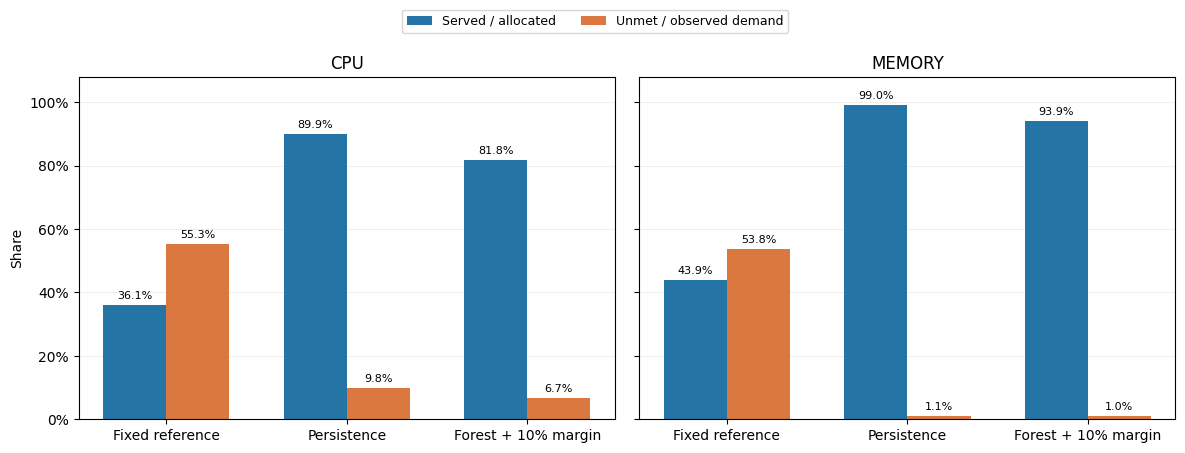

cpu forest matches persistence test risk tolerance: True | utilization change: -0.081 | unmet fraction change: -0.030
memory forest matches persistence test risk tolerance: True | utilization change: -0.051 | unmet fraction change: -0.001


In [23]:
test_policy_results = {
    "fixed": replay_policy(test, "fixed"),
    "persistence": replay_policy(test, "persistence"),
    "forest_plus_margin": replay_policy(test, "forest_plus_margin", margin=CHOSEN_MARGIN),
}
base_rows = []
for policy, per_resource in test_policy_results.items():
    for resource, metrics in per_resource.items():
        base_rows.append({"scenario": "original", "policy": policy, "resource": resource,
                          "margin": CHOSEN_MARGIN if policy == "forest_plus_margin" else 0.0,
                          **metrics})
base_table = pd.DataFrame(base_rows)
print("Held-out test policy comparison (resource amounts are normalized-resource-seconds):")
display(base_table[["policy", "resource", "utilization", "unused_resource_seconds",
                    "unmet_resource_seconds", "unmet_fraction", "overloaded_task_fraction",
                    "pool_saturation_fraction"]].round(4))

from matplotlib.ticker import PercentFormatter

policy_labels = ["Fixed reference", "Persistence", f"Forest + {CHOSEN_MARGIN:.0%} margin"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
positions = np.arange(len(POLICIES))
width = 0.35
for ax, resource in zip(axes, RESOURCES):
    rows = base_table.set_index(["resource", "policy"]).loc[resource].loc[POLICIES]
    for offset, metric, label, color in [
        (-width/2, "utilization", "Served / allocated", "#2474a6"),
        ( width/2, "unmet_fraction", "Unmet / observed demand", "#da7840"),
    ]:
        bars = ax.bar(positions + offset, rows[metric], width, label=label, color=color)
        ax.bar_label(bars, labels=[f"{value:.1%}" for value in rows[metric]],
                     padding=3, fontsize=8)
    ax.set(title=resource.upper(), xticks=positions, xticklabels=policy_labels,
           ylim=(0, 1.08))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
axes[0].set_ylabel("Share")
fig.legend(axes[0].containers, ["Served / allocated", "Unmet / observed demand"],
           loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.01), fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.93)); plt.show()
for resource in RESOURCES:
    persist = test_policy_results["persistence"][resource]
    forest = test_policy_results["forest_plus_margin"][resource]
    similar_risk = (forest["unmet_fraction"] <= persist["unmet_fraction"] + 0.01
                    and forest["overloaded_task_fraction"] <= persist["overloaded_task_fraction"] + 0.02)
    print(resource, "forest matches persistence test risk tolerance:", similar_risk,
          "| utilization change:", f"{forest['utilization']-persist['utilization']:+.3f}",
          "| unmet fraction change:", f"{forest['unmet_fraction']-persist['unmet_fraction']:+.3f}")


### What-if scenarios

For `+20%` and `+50%` workload, only the **observed demand used for scoring** is scaled. The three policies receive the same unshifted information they had in the original test period, and their requests stay frozen. For `-20% pool capacity`, the original demand and requests remain, but both resource pools shrink. There is no retraining or margin retuning. These are stress tests of the replay arithmetic, not claims about how real users or Borg would respond.


,scenario,policy,resource,utilization,unmet_fraction,overloaded_task_fraction,pool_saturation_fraction
0,original,fixed,cpu,0.3614,0.5527,0.2453,1.0000
1,original,fixed,memory,0.4387,0.5378,0.2521,1.0000
2,original,persistence,cpu,0.8994,0.0977,0.4409,0.0000
3,original,persistence,memory,0.9900,0.0112,0.3741,0.0000
4,original,forest_plus_margin,cpu,0.8184,0.0673,0.0911,0.4000
5,original,forest_plus_margin,memory,0.9395,0.0101,0.0888,1.0000
6,+20% demand,fixed,cpu,0.3821,0.6059,0.2727,1.0000
7,+20% demand,fixed,memory,0.4723,0.5853,0.2924,1.0000
8,+20% demand,persistence,cpu,0.9452,0.2098,0.8500,0.0000
9,+20% demand,persistence,memory,0.9969,0.1703,0.9393,0.0000


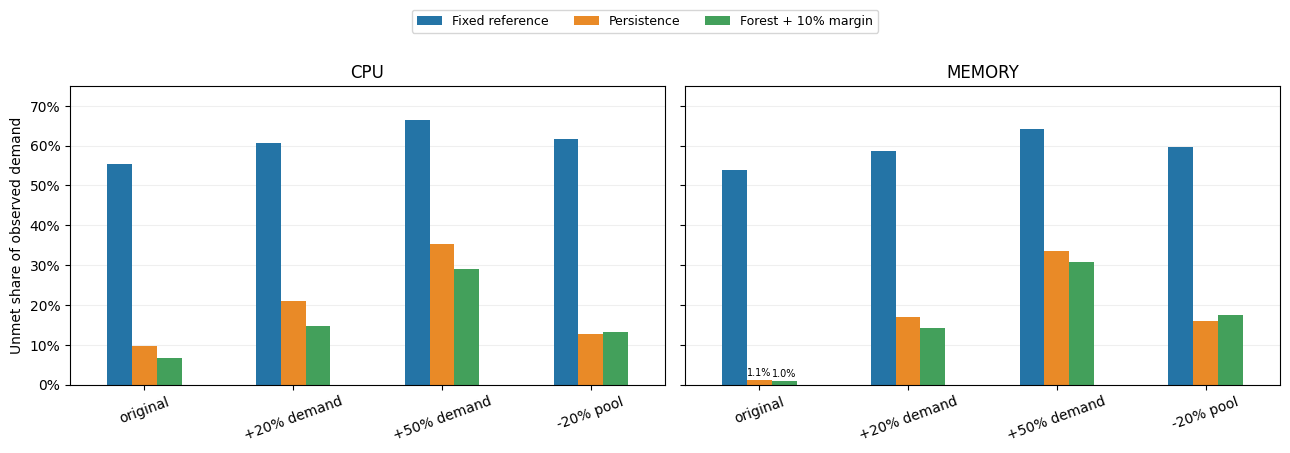

In [24]:
SCENARIOS = {
    "original": (1.0, 1.0),
    "+20% demand": (1.20, 1.0),
    "+50% demand": (1.50, 1.0),
    "-20% pool": (1.0, 0.80),
}
scenario_rows = []
for scenario, (demand_factor, capacity_factor) in SCENARIOS.items():
    for policy in POLICIES:
        result = replay_policy(test, policy,
                               margin=CHOSEN_MARGIN if policy == "forest_plus_margin" else 0.0,
                               demand_multiplier=demand_factor,
                               capacity_multiplier=capacity_factor)
        for resource in RESOURCES:
            scenario_rows.append({"scenario": scenario, "policy": policy, "resource": resource,
                                  "demand_factor": demand_factor,
                                  "capacity_factor": capacity_factor, **result[resource]})
scenario_table = pd.DataFrame(scenario_rows)
display(scenario_table[["scenario", "policy", "resource", "utilization",
                        "unmet_fraction", "overloaded_task_fraction",
                        "pool_saturation_fraction"]].round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, resource in zip(axes, RESOURCES):
    pivot = scenario_table.loc[scenario_table["resource"] == resource].pivot(
        index="scenario", columns="policy", values="unmet_fraction").reindex(SCENARIOS)
    pivot[POLICIES].plot.bar(ax=ax, color=["#2474a6", "#e98a27", "#43a05b"],
                             legend=False)
    ax.set(title=resource.upper(), xlabel="", ylim=(0, 0.75))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    # Tiny original-memory bars otherwise disappear against the baseline.
    if resource == "memory":
        for bar in ax.patches:
            if 0 < bar.get_height() < 0.03:
                ax.annotate(f"{bar.get_height():.1%}",
                            (bar.get_x() + bar.get_width()/2, bar.get_height()),
                            xytext=(0, 3), textcoords="offset points",
                            ha="center", fontsize=7)
axes[0].set_ylabel("Unmet share of observed demand")
fig.legend(axes[0].containers,
           ["Fixed reference", "Persistence", f"Forest + {CHOSEN_MARGIN:.0%} margin"],
           loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.01), fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.91)); plt.show()


### Final results and limitations

The notebook now covers workload characterization, next-interval demand forecasting, proxy risk classification, and a controlled policy replay. Interpret the three policies using **both** utilization and unmet demand. On the original test trace, the forest policy reduces CPU unmet share from 9.8% to 6.7% but also lowers CPU utilization from 89.9% to 81.8%; memory unmet share is about 1% for both policies. This is a reserve-capacity trade-off, not a utilization gain. Under a 20% smaller pool, forest unmet share is slightly higher than persistence for both resources. A policy can also have many task intervals with tiny shortfalls while leaving little total demand unmet. This selected eight-hour sample does not represent all 29 days or all machines. Usage is observed consumption, not unconstrained demand. The pool and proportional scaling are simulation assumptions; this does not reproduce machine placement, Borg scheduling, latency, SLA failures, or real cost savings. The Module 4 labels remain fixed proxy labels and are not verified bottlenecks.


In [25]:
conclusions = []
for resource in RESOURCES:
    persistence = test_policy_results["persistence"][resource]
    forest = test_policy_results["forest_plus_margin"][resource]
    risk_matched = (forest["unmet_fraction"] <= persistence["unmet_fraction"] + 0.01
                    and forest["overloaded_task_fraction"] <= persistence["overloaded_task_fraction"] + 0.02)
    utilization_gain = forest["utilization"] - persistence["utilization"]
    if risk_matched and utilization_gain > 0:
        conclusion = f"{resource}: forest improved useful utilization within the stated overload tolerance"
    elif risk_matched:
        conclusion = f"{resource}: forest matched overload tolerance but did not improve useful utilization"
    else:
        conclusion = f"{resource}: forest did not match persistence overload tolerance on test"
    conclusions.append(conclusion)

summary = {
    "module": 5,
    "trace_scope": "First six task_usage shards; identity-hash sample",
    "test_task_intervals": int(len(test)),
    "validation_task_intervals": int(len(validation)),
    "reference_allocation": reference,
    "training_pool_capacity": pool,
    "pool_capacity_rule": "95th percentile of aggregate observed training target usage per interval",
    "contention_rule": "Proportional scaling of requests independently for CPU and memory",
    "forest_margin": CHOSEN_MARGIN,
    "forest_margin_selection": margin_status,
    "margin_grid": MARGINS,
    "validation_margin_table": margin_table.to_dict(orient="records"),
    "test_baseline": base_rows,
    "scenarios": scenario_rows,
    "conclusions": conclusions,
    "limitations": [
        "Observed normalized usage is treated as demand; this is not unconstrained demand",
        "Pools represent the sampled task cohort, not real machine capacities",
        "No placement, latency, SLA, or real cost simulation",
        "Only a short initial trace window and selected task identities are represented",
        "Proxy bottleneck labels are not verified production failures",
    ],
}

def project_bytes():
    return sum(p.stat().st_size for root in (PROJECT_DIR / "data", PROJECT_DIR / "artifacts")
               for p in root.rglob("*") if p.is_file())

TEMP_JSON = M5_RESULTS_PATH.with_suffix(".json.part")
TEMP_CSV = M5_TABLE_PATH.with_suffix(".csv.part")
try:
    TEMP_JSON.write_text(json.dumps(summary, indent=2, allow_nan=False), encoding="utf-8")
    scenario_table.to_csv(TEMP_CSV, index=False)
    if project_bytes() > MAX_PROJECT_BYTES:
        raise RuntimeError("Module 5 outputs would exceed the 2.5 GB project cap")
    TEMP_JSON.replace(M5_RESULTS_PATH)
    TEMP_CSV.replace(M5_TABLE_PATH)
except Exception:
    TEMP_JSON.unlink(missing_ok=True)
    TEMP_CSV.unlink(missing_ok=True)
    raise
print("Saved final results:", M5_RESULTS_PATH)
print("Saved policy table:", M5_TABLE_PATH)
print("Project data/artifacts:", f"{project_bytes()/1e6:.1f} MB")
for conclusion in conclusions: print("Conclusion:", conclusion)
print("Interpret a utilization gain with substantially more unmet demand as a trade-off, not a free improvement.")


Saved final results: /content/drive/MyDrive/ml-project/artifacts/module5_results.json
Saved policy table: /content/drive/MyDrive/ml-project/artifacts/module5_policy_metrics.csv
Project data/artifacts: 565.8 MB
Conclusion: cpu: forest matched overload tolerance but did not improve useful utilization
Conclusion: memory: forest matched overload tolerance but did not improve useful utilization
Interpret a utilization gain with substantially more unmet demand as a trade-off, not a free improvement.
